✅ 中文显示设置成功
🟢 读取并清洗数据...
🟢 执行智能分词...
🟢 配置BERTopic...


No sentence-transformers model found with name uer/sbert-base-chinese-nli. Creating a new one with mean pooling.


🟢 计算文本嵌入...


Batches:   0%|          | 0/20 [00:00<?, ?it/s]

2025-05-27 07:43:17,644 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


🟢 训练BERTopic模型...


2025-05-27 07:43:20,236 - BERTopic - Dimensionality - Completed ✓
2025-05-27 07:43:20,238 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-05-27 07:43:20,336 - BERTopic - Cluster - Completed ✓
2025-05-27 07:43:20,340 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2025-05-27 07:43:20,734 - BERTopic - Representation - Completed ✓
2025-05-27 07:43:20,737 - BERTopic - Topic reduction - Reducing number of topics
2025-05-27 07:43:20,756 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-05-27 07:43:21,054 - BERTopic - Representation - Completed ✓
2025-05-27 07:43:21,057 - BERTopic - Topic reduction - Reduced number of topics from 16 to 16


🟢 计算聚类评价指标...
🔵 整体轮廓系数: 0.0383
🔵 Calinski-Harabasz指数: 11.49
🟢 训练分类器...
🟢 计算评估指标...
SVM 准确率: 0.7500 | F1-score: 0.6939
XGBoost 准确率: 0.8047 | F1-score: 0.7911


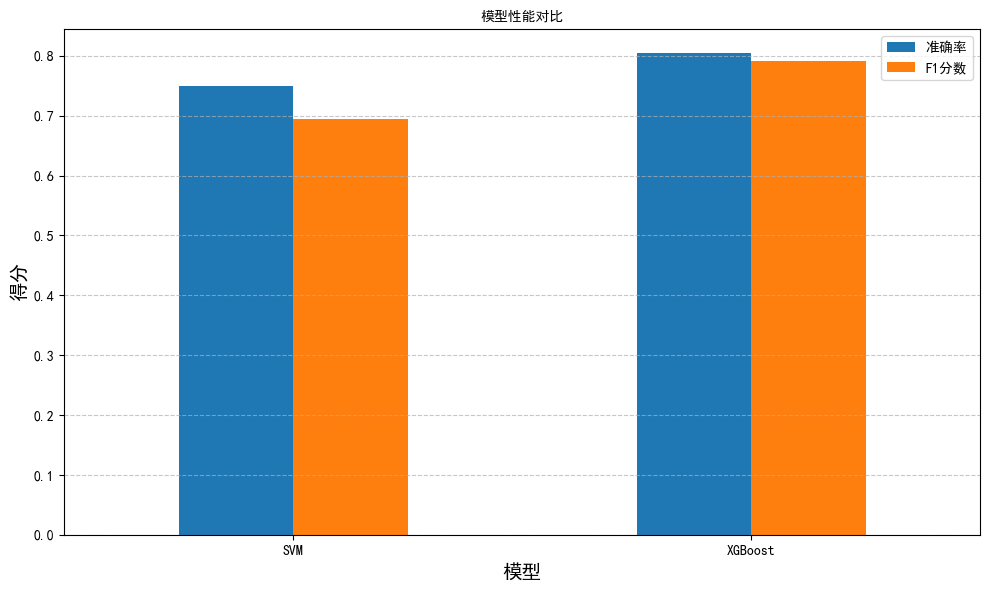

🟢 保存结果...
✅ 所有分类结果已保存！


In [13]:
import pandas as pd
import re
import jieba
import numpy as np
import time
import os
import seaborn as sns
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, silhouette_score, calinski_harabasz_score

# ----------------------
# 1. 中文显示全局设置
# ----------------------
try:
    plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows系统字体
    plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
    print("✅ 中文显示设置成功")
except Exception as e:
    print(f"⚠️ 中文显示设置失败，请检查系统字体: {e}")

# ----------------------
# 2. 数据预处理
# ----------------------
print("🟢 读取并清洗数据...")
def clean_text(text):
    text = re.sub(r'http\S+|www\S+|\d+|[^\u4e00-\u9fa5a-zA-Z]', ' ', str(text))
    text = re.sub(r'\s+', ' ', text).strip()
    return text if len(text) >= 10 else None

# 加载自定义词典
user_dict_content = """小米SU7 自动驾驶 雷军回应 ..."""  # 保持原有词典内容
with open("custom_dict.txt", "w", encoding="utf-8") as f:
    f.write(user_dict_content)
jieba.load_userdict("custom_dict.txt")

# 读取数据
data = pd.read_excel("测试数据.xlsx")

# 加载停用词
with open("Stopwords.txt", 'r', encoding='utf-8') as f:
    stopwords = [line.strip() for line in f]

# 分词处理
print("🟢 执行智能分词...")
def preprocess_text(text):
    text = clean_text(text)
    words = jieba.cut(text) if text else []
    return " ".join([word for word in words if word not in stopwords])

data['processed_content'] = data['news_content'].apply(preprocess_text)

# ----------------------
# 3. BERTopic 主题建模
# ----------------------
print("🟢 配置BERTopic...")

# 尝试提升轮廓系数的参数调整
embedding_model = SentenceTransformer("uer/sbert-base-chinese-nli")
vectorizer_model = TfidfVectorizer(
    max_features=12000,  # 增加特征数
    stop_words=stopwords,
    ngram_range=(1, 2)   # 使用1-2元语法
)
umap_model = UMAP(
    n_neighbors=5,        # 降低邻居数，提升局部结构
    n_components=5,       # 降低降维维度
    min_dist=0.0,         # 更紧密聚类
    metric='cosine',
    random_state=42
)

# 初始化BERTopic模型
topic_model = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    umap_model=umap_model,
    language='chinese',
    calculate_probabilities=True,
    verbose=True,
    nr_topics="auto"  # 自动合并小主题
)



# 计算文本嵌入
print("🟢 计算文本嵌入...")
# 确保输入为一维文本列表，与data['processed_content']长度一致
processed_texts = data['processed_content'].tolist()
text_embeddings = embedding_model.encode(processed_texts, show_progress_bar=True)

# 训练模型
print("🟢 训练BERTopic模型...")
topics, probs = topic_model.fit_transform(processed_texts, embeddings=text_embeddings)

# 计算轮廓系数和Calinski-Harabasz指数
print("🟢 计算聚类评价指标...")

valid_indices = np.array(topics) != -1
valid_topics = np.array(topics)[valid_indices]
valid_embeddings = np.array(text_embeddings)[valid_indices]

if len(set(valid_topics)) >= 2 and len(valid_topics) > 10:
    silhouette_avg = silhouette_score(valid_embeddings, valid_topics)
    ch_score = calinski_harabasz_score(valid_embeddings, valid_topics)
    print(f"🔵 整体轮廓系数: {silhouette_avg:.4f}")
    print(f"🔵 Calinski-Harabasz指数: {ch_score:.2f}")
else:
    print("⚠️ 有效主题不足，无法计算聚类评价指标")

# ----------------------
# 4. 训练分类器
# ----------------------
print("🟢 训练分类器...")
# 使用主题概率作为特征（每行为一个样本，每列为一个主题概率）
probs_2d = np.array(probs)  # shape: (n_samples, n_topics)
X_train, X_test, y_train, y_test = train_test_split(
    probs_2d, 
    data['keyword'], 
    test_size=0.2, 
    random_state=42
)

# 训练SVM
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train, y_train)
svm_preds = svm_model.predict(X_test)

# 训练XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train.values if hasattr(y_train, "values") else y_train)
xgb_preds = xgb_model.predict(X_test)

# ----------------------
# 5. 评估与可视化
# ----------------------
print("🟢 计算评估指标...")
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')
    print(f"{model_name} 准确率: {acc:.4f} | F1-score: {f1:.4f}")
    return acc, f1

svm_acc, svm_f1 = evaluate_model(y_test, svm_preds, "SVM")
xgb_acc, xgb_f1 = evaluate_model(y_test, xgb_preds, "XGBoost")

# 模型性能对比柱状图（中文）
def plot_model_comparison():
    metrics = pd.DataFrame({
        '模型': ['SVM', 'XGBoost'],
        '准确率': [svm_acc, xgb_acc],
        'F1分数': [svm_f1, xgb_f1]
    })
    plt.figure(figsize=(10, 6))
    ax = plt.subplot(111)
    metrics.set_index('模型').plot(kind='bar', ax=ax, rot=0)
    plt.title('模型性能对比', fontsize=16, fontproperties='SimHei')
    plt.ylabel('得分', fontsize=14, fontproperties='SimHei')
    plt.xlabel('模型', fontsize=14, fontproperties='SimHei')
    plt.legend(fontsize=12, prop={'family': 'SimHei'})
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_model_comparison()

# ----------------------
# 6. 结果保存
# ----------------------
print("🟢 保存结果...")
output_dir = "预测结果"
os.makedirs(output_dir, exist_ok=True)

test_indices = y_test.index  # 获取测试集的原始索引
test_data_with_predictions = pd.DataFrame({
    'news_content': data.loc[test_indices, 'news_content'].values,
    'keyword': y_test.values,
    'predicted_keyword_svm': svm_preds,
    'predicted_keyword_xgb': xgb_preds
})

# 按预测结果分组保存
for model_type in ['svm', 'xgb']:
    col_name = f'predicted_keyword_{model_type}'
    for keyword in test_data_with_predictions[col_name].unique():
        subset = test_data_with_predictions[test_data_with_predictions[col_name] == keyword]
        file_name = os.path.join(output_dir, f"话题检测_{keyword}_{model_type}.xlsx")
        subset.to_excel(file_name, index=False)

print("✅ 所有分类结果已保存！")

# 新增BERTopic主题可视化
try:
    fig = topic_model.visualize_topics()
    fig.update_layout(title_text='BERTopic主题可视化', title_x=0.5)
    fig.show()
except Exception as e:
    print(f"⚠️ 主题可视化失败: {str(e)}")

plt.rcParams['font.sans-serif'] = ['SimHei']  # 中文显示
plt.rcParams['axes.unicode_minus'] = False

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from wordcloud import WordCloud
from collections import Counter
from sklearn.metrics import calinski_harabasz_score

class TextClusteringVisualization:
    def __init__(self, stopwords_path=None):
        self.stopwords = self.load_stopwords(stopwords_path)
        self.vectorizer = TfidfVectorizer(max_features=5000)
        
    def load_stopwords(self, path):
        if path and os.path.exists(path):
            with open(path, 'r', encoding='utf-8') as f:
                return [line.strip() for line in f]
        return []

    def preprocess(self, texts):
        return [' '.join([word for word in jieba.lcut(str(text)) 
                        if word not in self.stopwords]) for text in texts]

    def fit(self, file_path, n_clusters=5, label_col=None):
        """主流程"""
        if file_path.endswith('.xlsx'):
            df = pd.read_excel(file_path, engine='openpyxl')
            texts = df.iloc[:, 0].astype(str).tolist()
            labels = df[label_col].values if label_col and label_col in df.columns else None
        else:
            with open(file_path, 'r', encoding='utf-8') as f:
                texts = [line.strip() for line in f]
            labels = None
        
        corpus = self.preprocess(texts)
        X = self.vectorizer.fit_transform(corpus)
        
        # K-means聚类
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        cluster_labels = kmeans.fit_predict(X)
        
        # 可视化（去除PCA降维聚类图）
        # self.plot_silhouette(X, cluster_labels)  # 已移除不存在的方法
        self.plot_wordclouds(corpus, cluster_labels)
        
        if labels is not None:
            self.train_and_evaluate(X, labels, corpus)
        
        return cluster_labels

    def plot_pca(self, X, labels, title):
        """PCA降维可视化"""
        pca = PCA(n_components=2)
        reduced = pca.fit_transform(X.toarray())
        
        plt.figure(figsize=(10, 6))
        scatter = plt.scatter(reduced[:, 0], reduced[:, 1], 
                            c=labels, cmap='viridis', alpha=0.6)
        plt.colorbar(scatter, label='簇编号')
        plt.title(title, fontproperties='SimHei', fontsize=16)
        plt.xlabel("主成分1", fontproperties='SimHei')
        plt.ylabel("主成分2", fontproperties='SimHei')
        plt.show()


    def plot_wordclouds(self, corpus, labels, n_top_words=20):
        """生成每个簇的词云图"""
        clustered_texts = {}
        for idx, label in enumerate(labels):
            if label not in clustered_texts:
                clustered_texts[label] = []
            clustered_texts[label].extend(corpus[idx].split())

        for cluster_id, words in clustered_texts.items():
            wordcloud = WordCloud(
                width=800,
                height=400,
                background_color='white',
                font_path='simhei.ttf'  # 确保有中文字体
            ).generate(' '.join(words))
            
            plt.figure(figsize=(10, 5))
            plt.imshow(wordcloud, interpolation='bilinear')
            plt.title(f"主题 {cluster_id} - 关键词词云", fontproperties='SimHei', fontsize=18)
            plt.axis("off")
            plt.show()
            
    def train_and_evaluate(self, X, y, corpus):
        """训练分类器并可视化结果"""
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42)
        
        # 训练模型
        models = {
            "SVM": SVC(kernel='linear'),
            "XGBoost": XGBClassifier(eval_metric='mlogloss')
        }
        
        results = []
        for name, model in models.items():
            model.fit(X_train, y_train)
            preds = model.predict(X_test)
            acc = accuracy_score(y_test, preds)
            f1 = f1_score(y_test, preds, average='weighted')
            results.append([name, acc, f1])
            
            # 混淆矩阵
            self.plot_confusion_matrix(y_test, preds, f"{name} 混淆矩阵")
        
        # 模型比较
        self.plot_model_comparison(results)
        
        # 特征重要性 (XGBoost)
        if "XGBoost" in models:
            self.plot_feature_importance(models["XGBoost"], corpus)

    def plot_model_comparison(self, results):
        """模型性能对比柱状图"""
        import matplotlib.pyplot as plt
        import pandas as pd
        metrics = pd.DataFrame(results, columns=['模型', '准确率', 'F1分数'])
        plt.figure(figsize=(10, 6))
        ax = plt.subplot(111)
        metrics.set_index('模型').plot(kind='bar', ax=ax, rot=0)
        plt.title('模型性能对比', fontsize=16, fontproperties='SimHei')
        plt.ylabel('得分', fontsize=14, fontproperties='SimHei')
        plt.xlabel('模型', fontsize=14, fontproperties='SimHei')
        plt.legend(fontsize=12, prop={'family': 'SimHei'})
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

    def plot_confusion_matrix(self, y_true, y_pred, title):
        """绘制混淆矩阵"""
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=np.unique(y_true),
                   yticklabels=np.unique(y_true))
        plt.xlabel('预测标签', fontproperties='SimHei')
        plt.ylabel('真实标签', fontproperties='SimHei')
        plt.title(title, fontproperties='SimHei', fontsize=16)
        plt.show()


    def plot_feature_importance(self, model, corpus, top_n=20):
        """XGBoost特征重要性"""
        if hasattr(model, 'feature_importances_'):
            feature_names = self.vectorizer.get_feature_names_out()
            importance = model.feature_importances_
            indices = np.argsort(importance)[-top_n:]
            plt.figure(figsize=(10, 6))
            plt.title("XGBoost重要特征", fontproperties='SimHei', fontsize=16)
            plt.barh(range(top_n), importance[indices], color='skyblue')
            plt.yticks(range(top_n), [feature_names[i] for i in indices], fontproperties='SimHei')
            plt.xlabel("特征重要性分数", fontproperties='SimHei')
            plt.ylabel("特征", fontproperties='SimHei')
            plt.show()

if __name__ == "__main__":
        file_path="测试数据.xlsx",  # 支持.txt或.xlsx
        n_clusters=5,
        label_col="keyword"  # 如果有标签列
    


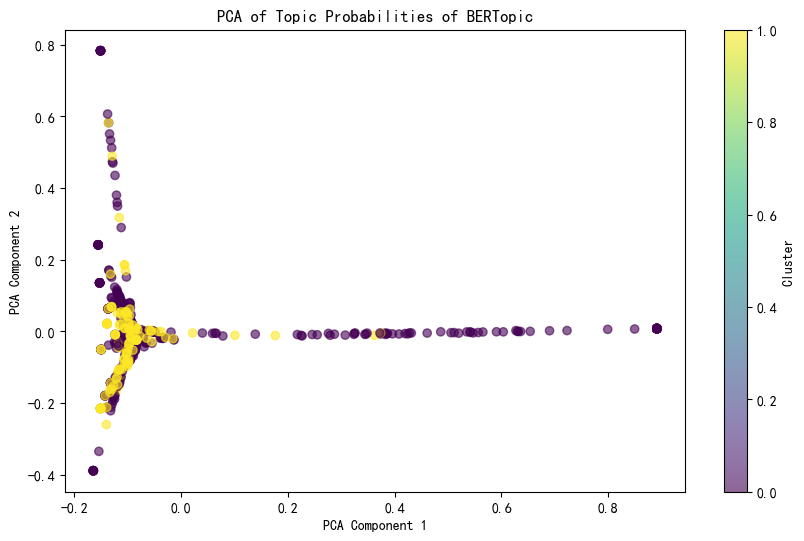

In [18]:
from sklearn.decomposition import PCA

def plot_pca(X, labels, title):
    """PCA降维可视化"""
    pca = PCA(n_components=2)
    reduced = pca.fit_transform(X)
    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(reduced[:, 0], reduced[:, 1], c=labels, cmap='viridis', alpha=0.6)
    plt.colorbar(scatter, label='Cluster')
    plt.title(title)
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.show()

# 示例：用主题概率和真实标签
plot_pca(probs_2d, data['keyword'], "PCA of Topic Probabilities of BERTopic")
